In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [5]:
data = pd.read_csv("Pumpkin_Seeds_Dataset.csv", encoding="latin1")


In [6]:
data.columns = [col.encode('ascii', 'ignore').decode('ascii').strip() for col in data.columns]
data['Class'] = data['Class'].str.encode('latin1').str.decode('utf-8', 'ignore')

print("\nDATASET PREVIEW")
print(data.head())


DATASET PREVIEW
        Area Perimeter Major_Axis_Length Minor_Axis_Length Convex_Area  \
0  56276.0 m   888.2 m           326.1 m           220.2 m   56831.0 m   
1  76631.0 m  1068.1 m           417.2 m           234.2 m   77280.0 m   
2  71623.0 m  1083.0 m           435.8 m           211.0 m   72663.0 m   
3  66458.0 m   992.1 m           381.6 m           222.5 m   67118.0 m   
4  66107.0 m   998.1 m           383.9 m           220.5 m   67117.0 m   

  Equiv_Diameter  Eccentricity  Solidity  Extent  Roundness  Aspect_Ration  \
0        267.7 m           0.7       1.0     0.7        0.9            1.5   
1        312.4 m           0.8       1.0     0.7        0.8            1.8   
2        302.0 m           0.9       1.0     0.7        0.8            2.1   
3        290.9 m           0.8       1.0     0.7        0.8            1.7   
4        290.1 m           0.8       1.0     0.7        0.8            1.7   

   Compactness       Class Average Radius         2xr  
0          0.

In [7]:
print(f"\nDataset Shape: {data.shape}")


Dataset Shape: (2500, 15)


In [8]:
for col in data.columns:
    if col != 'Class' and data[col].dtype == 'object':
        data[col] = data[col].str.replace(' m', '').astype(float)

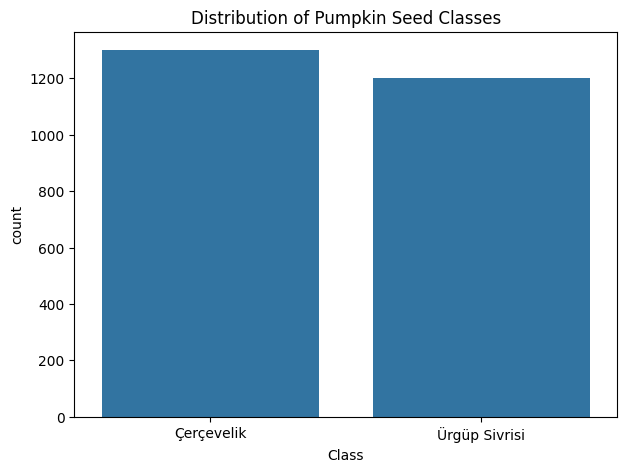

In [9]:
plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="Class")
plt.title("Distribution of Pumpkin Seed Classes")
plt.show()

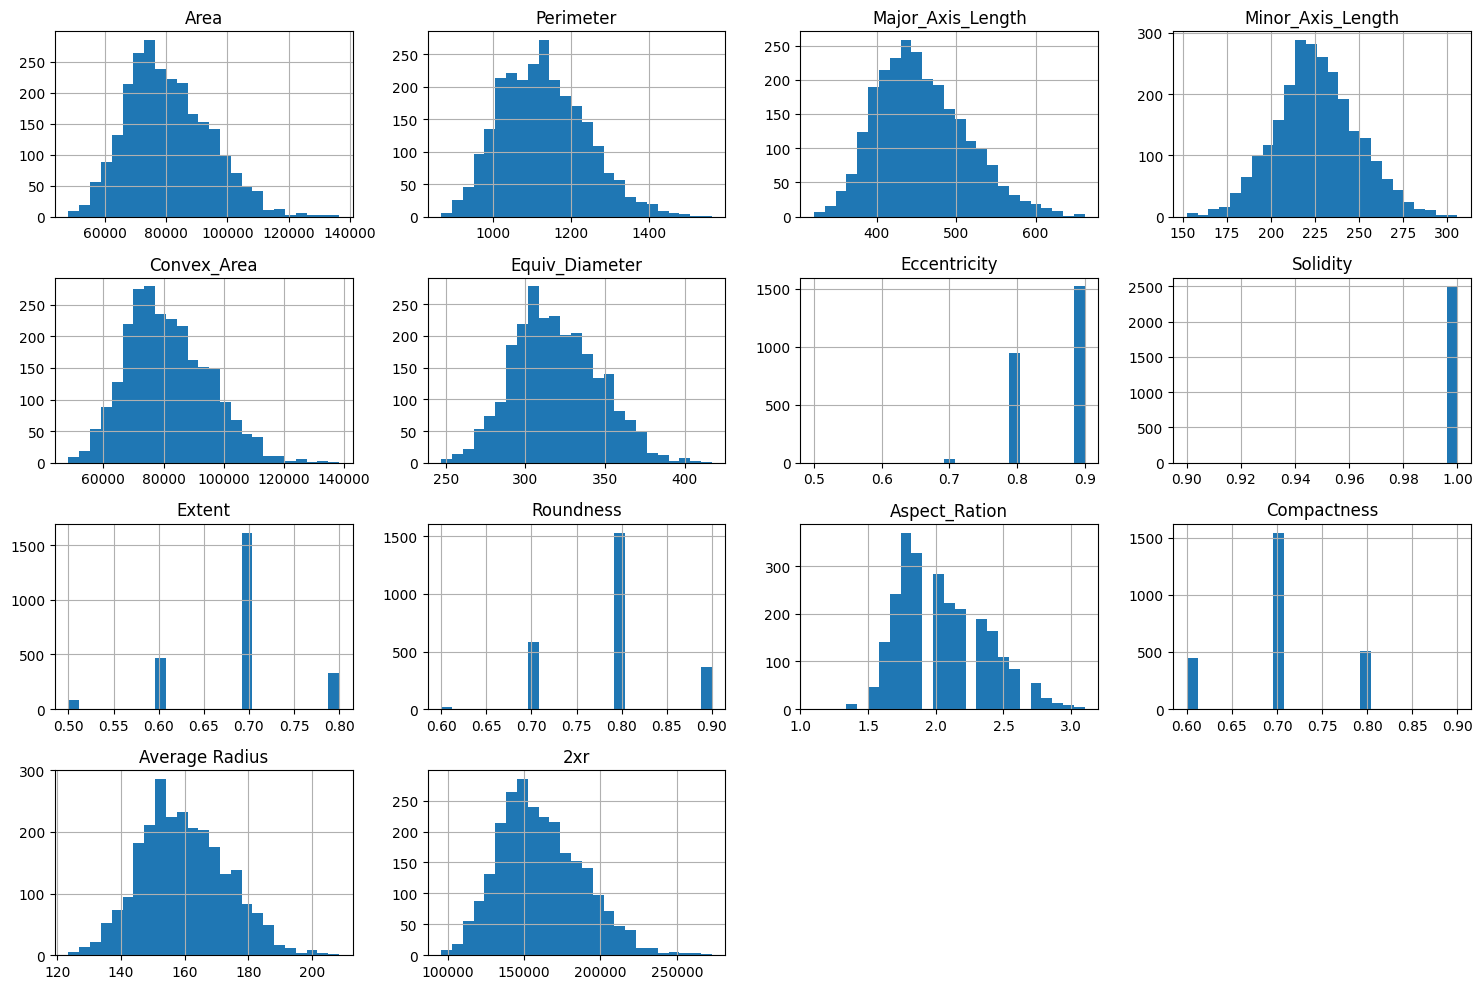

In [10]:
numerical_columns = data.select_dtypes(include=np.number).columns
data[numerical_columns].hist(figsize=(15, 10), bins=25)
plt.tight_layout()
plt.show()

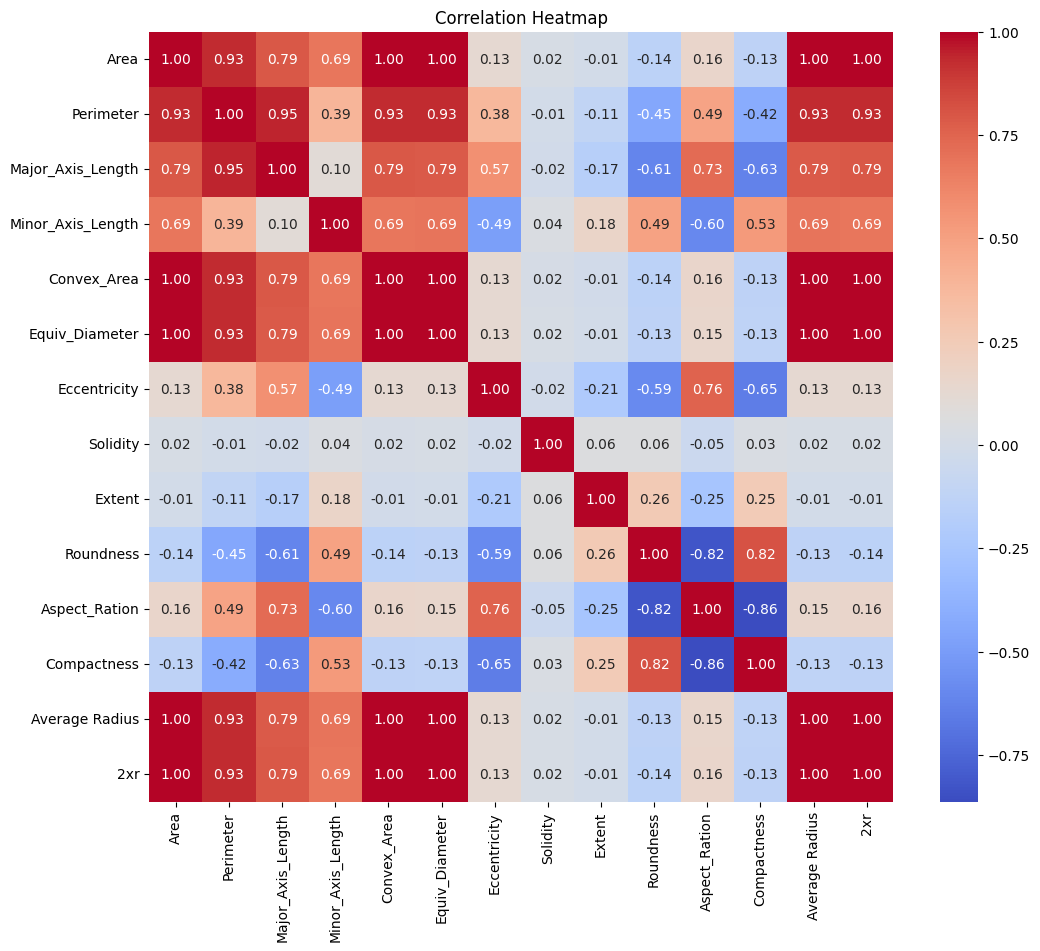

In [11]:
plt.figure(figsize=(12, 10))
sns.heatmap(data[numerical_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


Results:
Original Features: 14
PCA Components: 4
Accuracy Without PCA: 0.8620
Accuracy With PCA: 0.8400


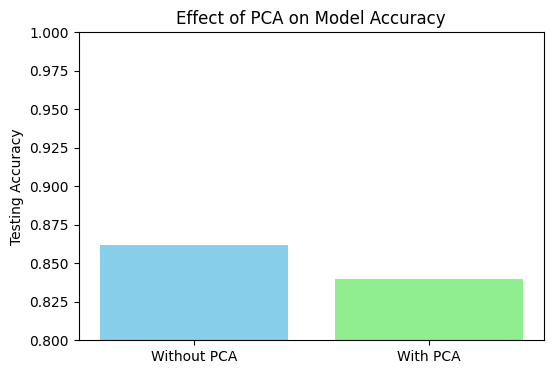

In [12]:
X = data.drop("Class", axis=1)
y = data["Class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model without PCA
model_no_pca = LogisticRegression(max_iter=2000).fit(X_train_scaled, y_train)
acc_no_pca = accuracy_score(y_test, model_no_pca.predict(X_test_scaled))

# Model with PCA (95% variance)
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

model_pca = LogisticRegression(max_iter=2000).fit(X_train_pca, y_train)
acc_pca = accuracy_score(y_test, model_pca.predict(X_test_pca))

print(f"\nResults:")
print(f"Original Features: {X.shape[1]}")
print(f"PCA Components: {pca.n_components_}")
print(f"Accuracy Without PCA: {acc_no_pca:.4f}")
print(f"Accuracy With PCA: {acc_pca:.4f}")

# Final Conclusion Visualization
plt.figure(figsize=(6, 4))
plt.bar(['Without PCA', 'With PCA'], [acc_no_pca, acc_pca], color=['skyblue', 'lightgreen'])
plt.ylabel('Testing Accuracy')
plt.title('Effect of PCA on Model Accuracy')
plt.ylim(0.8, 1.0)
plt.show()